# Analysis

The held-out score is the expected cost of the escalate-or-close rule, in units of $C_{FP}$ and $C_{MISS}$. It is compared with closing every matched alert. The reason slide in `presentation.qmd` has to agree with that cost. The risk slide is the risk of the action, not the log loss.


## Setup

The interpreter is Python 3.15.2, the version in `.python-version`. Packages are pinned in `requirements.txt`. The logistic fit is deterministic. The window simulation in the simulation section uses seed `20261116`. The notebook checks each local file against the SHA-256 in `data/README.md`.


In [1]:
import csv
import hashlib
import json
from collections import Counter, defaultdict
from datetime import datetime, timezone
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.preprocessing import OneHotEncoder

DATA = Path("data")
FIG = Path("fig")
FIG.mkdir(exist_ok=True)
LOCAL_TZ = ZoneInfo("America/New_York")
CUTOFF = datetime(2026, 10, 31, tzinfo=LOCAL_TZ)
SEED = 20261116
FILES = ["Days_61_90.csv", "Days_31_60.csv", "Days_01_30.csv", "DevToolStatus.csv"]
HASHES = {
    "Days_01_30.csv": "9403d78cb321eed6ebeffc61afc0b2d23b1ba5a4862fc35f51d3ac9afc2a9ed8",
    "Days_31_60.csv": "2fc71d8ae7ddd62bcfcc79bc8185de8abdab0046a37ad8344fb6c18984364e6e",
    "Days_61_90.csv": "1afa084a6d03297b553e8befe8fa876c7dee29194293622b0cf0c3930a480aab",
    "DevToolStatus.csv": "084887a9cbbe97b92d0032de0a0e4a9fd1d60a1a922e92bae8fecd053c654ba2",
}

def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

for name in FILES:
    digest = sha256(DATA / name)
    if digest != HASHES[name]:
        raise SystemExit(f"{name} hash {digest} does not match data/README.md")
print("SHA-256 checks passed")


SHA-256 checks passed


## Question

Which matched file-detection alerts should the SOC close, and which should it escalate? The quantity is the probability that the process which opened the file is Blocked on the product status list, one probability per alert, for alerts from 17 August 2026 through 16 November 2026. That probability is a stand-in for "malicious." The list was downloaded on 16 November 2026, and an analyst verdict is not recorded.

Escalating an allowed opener costs $C_{FP}$. Closing a blocked opener costs $C_{MISS}$. A correct call costs nothing. For an alert with probability $p$,

$$
\begin{aligned}
\text{expected cost of escalating} &= (1-p)\,C_{FP}, \\
\text{expected cost of closing} &= p\,C_{MISS}.
\end{aligned}
$$

Escalate when escalating is the smaller cost:

$$
p > \frac{C_{FP}}{C_{FP}+C_{MISS}}.
$$

The dollar amounts are not set, so the score stays in units of $C_{FP}$ and $C_{MISS}$.


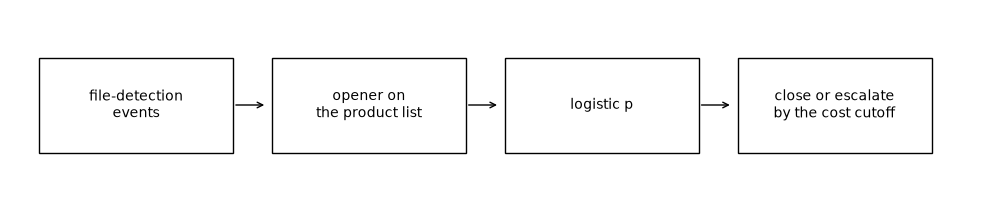

In [2]:
fig, ax = plt.subplots(figsize=(10, 2.2))
ax.set_xlim(0, 10)
ax.set_ylim(0, 2)
ax.axis("off")
boxes = [
    (0.3, "file-detection\nevents"),
    (2.7, "opener on\nthe product list"),
    (5.1, "logistic p"),
    (7.5, "close or escalate\nby the cost cutoff"),
]
for x, label in boxes:
    ax.add_patch(plt.Rectangle((x, 0.5), 2.0, 1.0, fill=False))
    ax.text(x + 1.0, 1.0, label, ha="center", va="center")
for x in (2.3, 4.7, 7.1):
    ax.annotate("", xy=(x + 0.35, 1.0), xytext=(x, 1.0), arrowprops=dict(arrowstyle="->"))
fig.tight_layout()
fig.savefig(FIG / "layers.png", dpi=120)
plt.show()


## Data

The events are a local endpoint-security export of file-detection events. They stay in `data/` and out of git. Each file has columns `_time` and `_raw`. The unit is one `uuid`, keeping the earliest device time when a `uuid` appears in more than one file. Repeated `uuid`s in these exports are identical copies.

The label is the 16 November 2026 status of `actor.app_name` on the product status list:

$$
y =
\begin{cases}
1 & \text{the opener is Blocked (G)}, \\
0 & \text{the opener is Approved, Recommended, Pre-introduced, or Conditionally usable}.
\end{cases}
$$

Not-recommended, phase-out, and a name that is both blocked and allowed stay out of the fit. An opener with no list row has no $y$ and is not scored. `file.name` matched a product name on 0 events, so the detected file is not the join.


rows in each export
Days_61_90.csv    31000
Days_31_60.csv    31000
Days_01_30.csv    29000
distinct uuid 27496
device time 2026-08-16 22:54:48.719000-04:00 -> 2026-11-16 12:45:28.512000-05:00
label counts {'unlabeled': 26264, 'y0': 1211, 'conflict': 4, 'mixed_exclude': 12, 'y1': 5}


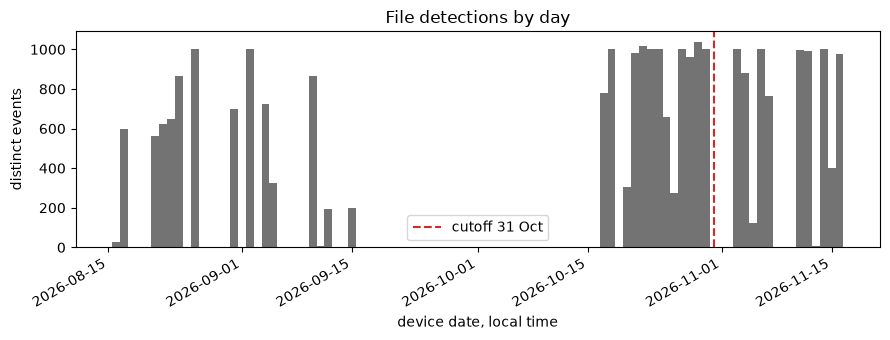

In [3]:
ALLOWED = {"O", "T", "M", "B"}
BLOCKED = {"G"}
EXCLUDE = {"U", "V", "PHASE"}
KEEP_EXT = {"pdf", "tmp", "csv", "dll", "exe", "ps1", "psm1"}

def norm(value):
    if not value:
        return ""
    text = " ".join(value.strip().lower().split())
    if text.endswith(".exe"):
        text = text[:-4].strip()
    return text

def status_code(text):
    text = (text or "").strip()
    if not text:
        return ""
    if text.lower().startswith("intended"):
        return "PHASE"
    return text.split(" ", 1)[0]

def label_of(codes):
    codes = set(codes)
    if codes & BLOCKED and codes & ALLOWED:
        return "conflict"
    if codes & EXCLUDE and not codes <= EXCLUDE:
        return "mixed_exclude"
    if codes <= EXCLUDE:
        return "exclude"
    if codes <= BLOCKED:
        return "y1"
    if codes <= ALLOWED:
        return "y0"
    return "other"

def extension_of(name):
    raw = (name or "").lower()
    if "." not in raw:
        return "(no dot)"
    suffix = raw.rsplit(".", 1)[-1]
    return suffix if suffix in KEEP_EXT else "other"

by_name = defaultdict(set)
with (DATA / "DevToolStatus.csv").open("r", encoding="utf-8", errors="replace", newline="") as handle:
    for row in csv.DictReader(handle):
        key = norm(row.get("prod_name"))
        code = status_code(row.get("u_dev_tool_status"))
        if key and code:
            by_name[key].add(code)
name_label = {key: label_of(codes) for key, codes in by_name.items()}

first = {}
file_rows = {}
for fname in ["Days_61_90.csv", "Days_31_60.csv", "Days_01_30.csv"]:
    n = 0
    with (DATA / fname).open("r", encoding="utf-8", errors="replace", newline="") as handle:
        for row in csv.DictReader(handle):
            n += 1
            event = json.loads(row["_raw"])
            uid = event.get("uuid")
            when = datetime.fromtimestamp(
                float(event.get("device_time") or event.get("time")) / 1000,
                tz=timezone.utc,
            ).astimezone(LOCAL_TZ)
            actor = event.get("actor") or {}
            app = norm(actor.get("app_name") if isinstance(actor, dict) else "")
            file_obj = event.get("file") or {}
            record = {
                "when": when,
                "lab": name_label.get(app, "unlabeled"),
                "app": app,
                "device": event.get("device_uid") or "",
                "feature": event.get("feature_name") or "(none)",
                "disp": str(event.get("id")),
                "severity": str(event.get("severity_id")),
                "reason": str(event.get("reason_id")),
                "ext": extension_of(file_obj.get("name") if isinstance(file_obj, dict) else ""),
                "hour": when.hour,
            }
            if uid not in first or when < first[uid]["when"]:
                first[uid] = record
    file_rows[fname] = n

summary = pd.DataFrame({
    "rows": file_rows,
    "note": "row count before dropping duplicate uuid copies",
})
print("rows in each export")
print(summary["rows"].to_string())
print("distinct uuid", len(first))
print("device time", min(r["when"] for r in first.values()), "->", max(r["when"] for r in first.values()))
print("label counts", dict(Counter(r["lab"] for r in first.values())))

days = Counter(r["when"].date() for r in first.values())
order = sorted(days)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(order, [days[key] for key in order], color="0.45", width=1.0)
ax.axvline(CUTOFF.date(), color="C3", ls="--", label="cutoff 31 Oct")
ax.set_ylabel("distinct events")
ax.set_xlabel("device date, local time")
ax.set_title("File detections by day")
fig.autofmt_xdate()
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "daily_events.png", dpi=120)
plt.show()


## Split

The decision is about a later alert, so the holdout is a later time. Train on device times before 31 October 2026 00:00 local time. Hold out device times on or after that cutoff. The five blocked openers all fall on 29 October, before the cutoff. Alerts with no y, and the conflict and mixed-exclusion labels, are not scored.


In [4]:
prior_devices = defaultdict(set)
for record in sorted(first.values(), key=lambda item: item["when"]):
    if record["when"] >= CUTOFF or not record["app"]:
        continue
    record["prior_devices"] = len(prior_devices[record["app"]])
    if record["device"]:
        prior_devices[record["app"]].add(record["device"])
for record in first.values():
    if record["when"] >= CUTOFF and record["app"]:
        record["prior_devices"] = len(prior_devices[record["app"]])
    record.setdefault("prior_devices", 0)

matched = [record for record in first.values() if record["lab"] in {"y0", "y1"}]
train = [record for record in matched if record["when"] < CUTOFF]
test = [record for record in matched if record["when"] >= CUTOFF]
y_train = np.array([record["lab"] == "y1" for record in train], dtype=int)
y_test = np.array([record["lab"] == "y1" for record in test], dtype=int)
print("train", len(train), "blocked", int(y_train.sum()), "allowed", int((y_train == 0).sum()))
print("test", len(test), "blocked", int(y_test.sum()), "allowed", int((y_test == 0).sum()))
positives = [record for record in train if record["lab"] == "y1"]
print(
    "blocked alerts: distinct openers", len({r["app"] for r in positives}),
    "distinct devices", len({r["device"] for r in positives}),
    "span minutes", round((max(r["when"] for r in positives) - min(r["when"] for r in positives)).total_seconds() / 60, 2),
)


train 1077 blocked 5 allowed 1072
test 139 blocked 0 allowed 139
blocked alerts: distinct openers 1 distinct devices 1 span minutes 1.9


## Baseline

Close every matched alert. On the held-out matched alerts there is no blocked opener, so

$$
\text{cost of closing every alert} = 0.
$$

A rule that escalates $k$ of them, all allowed, costs

$$
k\,C_{FP}.
$$


In [5]:
baseline_cost = f"0 * C_MISS = 0 on {len(test)} held-out matched alerts"
print(baseline_cost)


0 * C_MISS = 0 on 139 held-out matched alerts


## Model

Logistic regression, fitted by log loss on the training alerts. $y_i = 1$ when the opener is Blocked.

$$
p_i = \frac{1}{1+\exp\!\left(-(\beta_0 + x_i^{\top}\beta)\right)}.
$$

$$
\text{log loss} = -\frac{1}{n}\sum_{i=1}^{n}\Bigl[y_i\log p_i + (1-y_i)\log(1-p_i)\Bigr].
$$

$\beta_0$ is the log-odds for the reference pattern. Each other coefficient is a change in the log-odds of the opener being Blocked. One more unit of input $j$ multiplies the odds by $e^{\beta_j}$. The inputs are the detection feature, disposition, severity, reason, file extension, hour, and the log of how many devices had already run that opener before the cutoff. The opener's name and the list status are not inputs: the label is a function of those.

When every held-out label is $0$, predicting the training rate $\bar y$ for every alert has log loss

$$
-\log(1-\bar y).
$$

The assumption trusted least is that these five blocked alerts are five independent examples. They are one opener on one device, less than two minutes apart, and they share the detection fields of the allowed alerts. The unpenalized fit is the week 7 model. An L2 fit with $C = 1$ is reported beside it because a coefficient that large is separation, not a stable probability.


In [6]:
def design(records, encoder=None):
    cats = [[r["feature"], r["disp"], r["severity"], r["reason"], r["ext"]] for r in records]
    nums = np.array([[r["hour"], np.log1p(r["prior_devices"])] for r in records], dtype=float)
    if encoder is None:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
        encoded = encoder.fit_transform(cats)
    else:
        encoded = encoder.transform(cats)
    return np.column_stack([encoded, nums]), encoder

def heldout_cost(p, y, ratio):
    """ratio = C_MISS / C_FP. Escalate when p > 1 / (1 + ratio)."""
    cutoff = 1 / (1 + ratio)
    escalate = p > cutoff
    false_pos = int((escalate & (y == 0)).sum())
    misses = int((~escalate & (y == 1)).sum())
    return cutoff, false_pos, misses

x_train, encoder = design(train)
x_test, _ = design(test, encoder)
base_rate = float(y_train.mean())
constant = np.full(len(y_test), base_rate)
print(f"training rate {base_rate:.4f}")
print(f"constant-rate held-out log loss {-np.log(1 - base_rate):.4f}")

fits = {}
for name, kwargs in (
    ("unpenalized", {"C": np.inf}),
    ("l2_C1", {"C": 1.0, "l1_ratio": 0}),
):
    model = LogisticRegression(solver="lbfgs", max_iter=500, **kwargs)
    model.fit(x_train, y_train)
    p_test = model.predict_proba(x_test)[:, 1]
    fits[name] = p_test
    p_train = model.predict_proba(x_train)[:, 1]
    print(
        name,
        "max |coef|", round(float(np.max(np.abs(model.coef_))), 3),
        "train log loss", round(log_loss(y_train, p_train, labels=[0, 1]), 4),
        "test log loss", round(log_loss(y_test, np.clip(p_test, 1e-6, 1 - 1e-6), labels=[0, 1]), 4),
        "test p max", round(float(p_test.max()), 4),
    )
    for ratio in (1, 9):
        cutoff, false_pos, misses = heldout_cost(p_test, y_test, ratio)
        print(f"  C_MISS/C_FP={ratio} cutoff={cutoff:.4f} false positives={false_pos} misses={misses} cost={false_pos} C_FP + {misses} C_MISS")

print("close every alert: false positives=0 misses=0 cost=0")


training rate 0.0046
constant-rate held-out log loss 0.0047
unpenalized max |coef| 64.905 train log loss 0.0117 test log loss 0.0993 test p max 0.8193
  C_MISS/C_FP=1 cutoff=0.5000 false positives=8 misses=0 cost=8 C_FP + 0 C_MISS
  C_MISS/C_FP=9 cutoff=0.1000 false positives=9 misses=0 cost=9 C_FP + 0 C_MISS
l2_C1 max |coef| 2.635 train log loss 0.0159 test log loss 0.1418 test p max 0.4322
  C_MISS/C_FP=1 cutoff=0.5000 false positives=0 misses=0 cost=0 C_FP + 0 C_MISS
  C_MISS/C_FP=9 cutoff=0.1000 false positives=52 misses=0 cost=52 C_FP + 0 C_MISS
close every alert: false positives=0 misses=0 cost=0


## Simulation check

Two checks. The window check draws the number of blocked alerts in a held-out window of the same size,

$$
N \sim \mathrm{Binomial}(n_{\text{test}}, \bar y_{\text{train}}),
$$

with seed `20261116`. It asks how often that window contains no blocked opener if the training rate is real. The separation check fits the unpenalized model to a design where five rows are positive and the rest are negative, with one column that marks only those five. A finite slope cannot be recovered: the coefficient grows because the classes do not overlap.


In [7]:
rng = np.random.default_rng(SEED)
draws = rng.binomial(len(test), base_rate, size=10000)
print(f"expected blocked alerts in a window of {len(test)}: {draws.mean():.2f}")
print(f"share of draws with none: {(draws == 0).mean():.3f}")

x_sep = np.array([[0.0]] * int((y_train == 0).sum()) + [[1.0]] * int(y_train.sum()))
y_sep = np.array([0] * int((y_train == 0).sum()) + [1] * int(y_train.sum()))
separated = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=200)
separated.fit(x_sep, y_sep)
print("separated design coefficient", round(float(separated.coef_[0, 0]), 3), "intercept", round(float(separated.intercept_[0]), 3))


expected blocked alerts in a window of 139: 0.65
share of draws with none: 0.524
separated design coefficient 13.721 intercept -9.269


## Residuals and calibration

Every held-out matched alert is an allowed opener, so a probability near $1$ is a false escalation, not a noisy miss around a real attack. The unpenalized probabilities are plotted below. The constant training rate $\bar y$ is the reference: it is the probability the cost rule can use without memorizing the five training alerts.


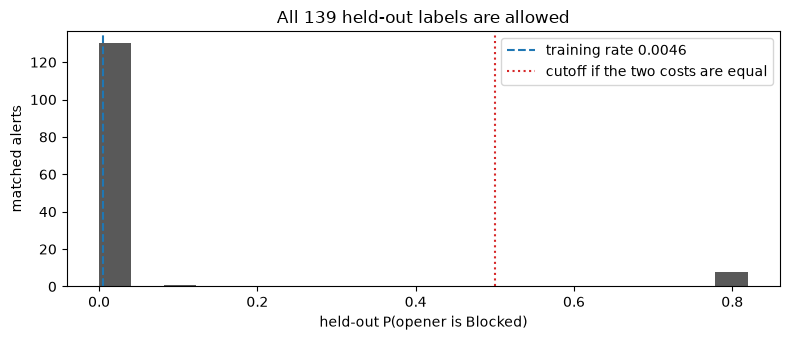

unpenalized alerts with p > 0.5: 8


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(fits["unpenalized"], bins=20, color="0.35")
ax.axvline(base_rate, color="C0", ls="--", label=f"training rate {base_rate:.4f}")
ax.axvline(0.5, color="C3", ls=":", label="cutoff if the two costs are equal")
ax.set_xlabel("held-out P(opener is Blocked)")
ax.set_ylabel("matched alerts")
ax.set_title("All 139 held-out labels are allowed")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "heldout_p.png", dpi=120)
plt.show()
print("unpenalized alerts with p > 0.5:", int((fits["unpenalized"] > 0.5).sum()))


## Decision

Close every matched alert. Its held-out cost is $0$. The scored cost of a rule is

$$
n_{FP}\,C_{FP} + n_{MISS}\,C_{MISS},
$$

where $n_{FP}$ is the number of allowed openers it escalates and $n_{MISS}$ is the number of blocked openers it closes. On this held-out set $n_{MISS} = 0$ for every rule, because there is no blocked opener to catch.

The unpenalized logistic rule, at equal costs, escalates allowed openers, so its cost is a positive multiple of $C_{FP}$. The L2 fit ties closing every alert when $C_{MISS} = C_{FP}$. It costs more when $C_{MISS} = 9\,C_{FP}$, because the lower cutoff escalates allowed openers and still catches none.

The action does not change if the main inputs move inside this held-out window: there is no blocked opener there for the rule to catch. A blocked opener after 31 October, from a process the fit had seen on an earlier day, is what would make escalating worth a positive $C_{FP}$.


In [9]:
rows = []
for name, p in fits.items():
    for ratio in (1, 9):
        cutoff, false_pos, misses = heldout_cost(p, y_test, ratio)
        rows.append({
            "rule": name,
            "C_MISS/C_FP": ratio,
            "cutoff": round(cutoff, 4),
            "false_positives": false_pos,
            "misses": misses,
            "cost": f"{false_pos} C_FP + {misses} C_MISS",
        })
rows.append({
    "rule": "close every alert",
    "C_MISS/C_FP": "any",
    "cutoff": None,
    "false_positives": 0,
    "misses": 0,
    "cost": "0",
})
from IPython.display import Markdown, display

def cost_tex(false_pos, misses):
    return rf"${false_pos}\,C_{{FP}} + {misses}\,C_{{MISS}}$"

lines = [
    r"| Rule | $C_{MISS}/C_{FP}$ | cutoff | cost |",
    r"|---|---:|---:|---|",
]
for row in rows:
    cutoff = "—" if row["cutoff"] is None else f"${row['cutoff']}$"
    ratio = row["C_MISS/C_FP"]
    ratio_tex = r"any" if ratio == "any" else f"${ratio}$"
    lines.append(
        f"| {row['rule']} | {ratio_tex} | {cutoff} | {cost_tex(row['false_positives'], row['misses'])} |"
    )
display(Markdown("\n".join(lines)))


| Rule | $C_{MISS}/C_{FP}$ | cutoff | cost |
|---|---:|---:|---|
| unpenalized | $1$ | $0.5$ | $8\,C_{FP} + 0\,C_{MISS}$ |
| unpenalized | $9$ | $0.1$ | $9\,C_{FP} + 0\,C_{MISS}$ |
| l2_C1 | $1$ | $0.5$ | $0\,C_{FP} + 0\,C_{MISS}$ |
| l2_C1 | $9$ | $0.1$ | $52\,C_{FP} + 0\,C_{MISS}$ |
| close every alert | any | — | $0\,C_{FP} + 0\,C_{MISS}$ |

## Limits

The label is today's status of the opening process, not an analyst's verdict and not a property of the detected file. The product status list is dated 16 November 2026, after the cutoff, so a status that changed because of a later incident is baked into the training label. The five blocked alerts are one incident. The unmatched alerts, about 26,000 of the 27,496 events, have no y, and the cost is not computed on them.

The model should not be used to escalate, and it should not be used to judge an employee. A person makes the call. With more time, the useful addition is a blocked opener that appears on an earlier day and again after the cutoff, or a recorded analyst verdict joined on `uuid`. Until then the lower held-out cost is to close every matched alert.
